## Ejercicio hiperparametrización breast cancer de sklearn

1. Carga el dataset [breast_cancer de `sklearn`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html)
2. Prueba al menos 5 modelos diferentes de clasificación y aplica un GridSearchCV mediante Pipelines. Aplica también un RandomizedSearchCV.
3. Conclusiones. Guarda el modelo final en un archivo con pickle.

In [8]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer

In [9]:
%matplotlib inline
data = load_breast_cancer()
data

{'data': array([[1.799e+01, 1.038e+01, 1.228e+02, ..., 2.654e-01, 4.601e-01,
         1.189e-01],
        [2.057e+01, 1.777e+01, 1.329e+02, ..., 1.860e-01, 2.750e-01,
         8.902e-02],
        [1.969e+01, 2.125e+01, 1.300e+02, ..., 2.430e-01, 3.613e-01,
         8.758e-02],
        ...,
        [1.660e+01, 2.808e+01, 1.083e+02, ..., 1.418e-01, 2.218e-01,
         7.820e-02],
        [2.060e+01, 2.933e+01, 1.401e+02, ..., 2.650e-01, 4.087e-01,
         1.240e-01],
        [7.760e+00, 2.454e+01, 4.792e+01, ..., 0.000e+00, 2.871e-01,
         7.039e-02]], shape=(569, 30)),
 'target': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
        0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0,
        1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0,
        1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1,
        1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1,

In [10]:
data.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])

In [11]:
print(data['DESCR'])

.. _breast_cancer_dataset:

Breast cancer Wisconsin (diagnostic) dataset
--------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 569

:Number of Attributes: 30 numeric, predictive attributes and the class

:Attribute Information:
    - radius (mean of distances from center to points on the perimeter)
    - texture (standard deviation of gray-scale values)
    - perimeter
    - area
    - smoothness (local variation in radius lengths)
    - compactness (perimeter^2 / area - 1.0)
    - concavity (severity of concave portions of the contour)
    - concave points (number of concave portions of the contour)
    - symmetry
    - fractal dimension ("coastline approximation" - 1)

    The mean, standard error, and "worst" or largest (mean of the three
    worst/largest values) of these features were computed for each image,
    resulting in 30 features.  For instance, field 0 is Mean Radius, field
    10 is Radius SE, field 20 is Worst Radius.

    - 

In [12]:
df = pd.DataFrame(data['data'], columns=data['feature_names'])
df['target'] = data['target']
df

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,0
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,0
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,0
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,0


In [ ]:
from data_profiling import ProfileReport #crea un EDA automatico

c:\Users\haize\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [13]:
profile = ProfileReport(df, title="Profiling Report")
profile.to_file("your_report.html")

Export report to file: 100%|██████████| 1/1 [00:00<00:00,  2.17it/s]


In [6]:
import warnings

warnings.filterwarnings("ignore", category=DeprecationWarning)

In [8]:
from sklearn.model_selection import train_test_split

X = df.drop('target', axis=1)
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y   # mantiene la proporción de clases en train y test
)

print(X_train.shape, X_test.shape)

(455, 30) (114, 30)


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Cada modelo: (pipeline, diccionario de parámetros a probar)
#SVC().get_params()   # muestra todos los parámetros y sus valores por defecto
modelos = {
    'Logistic Regression': {
        'pipeline': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', LogisticRegression(max_iter=1000))
        ]),
        'params': {
            'clf__C': [0.01, 0.1, 1, 10, 100], # cuando es más pequeño es un modelo más simple, cuando es más grande es un modelo más complejo
            'clf__penalty': ['l2']
        }
    },
    'SVM': { # la calle en el gráfico, más estrecha o más ancha, es el margen que separa las clases. Si es más estrecha, el modelo es más complejo y puede sobreajustar. Si es más ancha, el modelo es más simple y puede subajustar.
        'pipeline': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', SVC())
        ]),
        'params': {
            'clf__C': [0.1, 1, 10], #cuanto más pequeño modelo más simple
            'clf__kernel': ['linear', 'rbf'], # el kernel define la forma de la frontera de decisión, osea la curva que separa las clases. Si es lineal, es una línea recta. Si es rbf, es una curva más compleja.
            'clf__gamma': ['scale', 'auto'] # el parámetro gamma define la influencia de un solo punto de entrenamiento. Si es 'scale', el valor de gamma se calcula automáticamente en función del número de características y el número de muestras. Si es 'auto', el valor de gamma se establece en 1/n_features.
        } 
    },
    'KNN': {
        'pipeline': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', KNeighborsClassifier())
        ]),
        'params': {
            'clf__n_neighbors': [3, 5, 7, 9, 11], # el número de vecinos a considerar para la clasificación. Un valor más pequeño puede llevar a un modelo más complejo y sobreajustado, puede llegar a ser overfit, mientras que un valor más grande puede llevar a un modelo más simple y subajustado, underfit
            'clf__weights': ['uniform', 'distance']
        }
    },
    'Decision Tree': {
        'pipeline': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', DecisionTreeClassifier(random_state=42))
        ]),
        'params': {
            'clf__max_depth': [3, 5, 7, 10, None], # más profundo riesgo a sobreajuste
            'clf__min_samples_split': [2, 5, 10]
        }
    },
    'Random Forest': {
        'pipeline': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', RandomForestClassifier(random_state=42))
        ]),
        'params': {
            'clf__n_estimators': [50, 100, 200], #nº de arboles
            'clf__max_depth': [5, 10, None], #complejidad del arbol, más profundo riesgo a sobreajuste
            'clf__min_samples_split': [2, 5]
        }
    }
}
# va a probar todas estas combinaciones de parámetros para cada modelo y va a devolver el mejor modelo para cada uno de ellos, cada modelo.

In [ ]:
from sklearn.model_selection import GridSearchCV

resultados_grid = []
mejores_grid = {}   # guardamos el mejor pipeline de cada modelo, el diccionario es para que aparezcan los datos en columnas

for nombre, cfg in modelos.items(): # cfg pasa por modelos.items(un diccionario hecho antes)
    print(f"Entrenando {nombre}...")
    
    grid = GridSearchCV(
        estimator=cfg['pipeline'], #modelo que pilla cads modelo, se pone pipelinne a los elementos
        param_grid=cfg['params'],
        cv=5,               # validación cruzada de 5 folds
        scoring='accuracy',
        n_jobs=-1           # usa todos los núcleos del procesador
    )
    grid.fit(X_train, y_train)
    
    mejores_grid[nombre] = grid.best_estimator_
    resultados_grid.append({
        'Modelo': nombre,
        'Mejor CV accuracy': grid.best_score_,
        'Mejores parámetros': grid.best_params_
    })

df_grid = pd.DataFrame(resultados_grid).sort_values('Mejor CV accuracy', ascending=False)
df_grid

Entrenando Logistic Regression...


c:\Users\haize\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Entrenando SVM...
Entrenando KNN...
Entrenando Decision Tree...
Entrenando Random Forest...


,Modelo,Mejor CV accuracy,Mejores parámetros
0,Logistic Regression,0.980220,"{'clf__C': 0.1, 'clf__penalty': 'l2'}"
1,SVM,0.978022,"{'clf__C': 0.1, 'clf__gamma': 'scale', 'clf__k..."
2,KNN,0.971429,"{'clf__n_neighbors': 7, 'clf__weights': 'unifo..."
4,Random Forest,0.958242,"{'clf__max_depth': 10, 'clf__min_samples_split..."
3,Decision Tree,0.938462,"{'clf__max_depth': 5, 'clf__min_samples_split'..."


In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform, randint

# Reutilizamos los mismos pipelines, con espacios de búsqueda más amplios
modelos_random = {
    'Logistic Regression': {
        'pipeline': modelos['Logistic Regression']['pipeline'],
        'params': {
            'clf__C': loguniform(1e-3, 1e3)   # continuo, escala logarítmica, entre 0.001 y 1000, para que busque en un rango más amplio de valores
        }
    },
    'SVM': {
        'pipeline': modelos['SVM']['pipeline'],
        'params': {
            'clf__C': loguniform(1e-2, 1e2), #10 a la menos 2 a 10 a la 2, 0.01 a 100
            'clf__kernel': ['linear', 'rbf'],
            'clf__gamma': loguniform(1e-4, 1e0) #de 0.0001 a 1,
        }
    },
    'KNN': {
        'pipeline': modelos['KNN']['pipeline'],
        'params': {
            'clf__n_neighbors': randint(1, 31), #enteros entre el 1 y el 30
            'clf__weights': ['uniform', 'distance']
        }
    },
    'Decision Tree': {
        'pipeline': modelos['Decision Tree']['pipeline'],
        'params': {
            'clf__max_depth': randint(2, 15),
            'clf__min_samples_split': randint(2, 20)
        }
    },
    'Random Forest': {
        'pipeline': modelos['Random Forest']['pipeline'],
        'params': {
            'clf__n_estimators': randint(50, 300),
            'clf__max_depth': randint(3, 20),
            'clf__min_samples_split': randint(2, 10)
        }
    }
}

resultados_random = []
mejores_random = {}

for nombre, cfg in modelos_random.items():
    print(f"Entrenando {nombre}...")
    
    rnd = RandomizedSearchCV(
        estimator=cfg['pipeline'],
        param_distributions=cfg['params'],
        n_iter=30,           # nº de combinaciones al azar a probar por modelo, diferente al GridSearchCV que prueba todas las combinaciones posibles, aquí solo prueba 30 combinaciones al azar
        cv=5,
        scoring='accuracy',
        n_jobs=-1,
        random_state=42      # para que sea reproducible y siempre de los mismos resultados
    )
    rnd.fit(X_train, y_train)
    
    mejores_random[nombre] = rnd.best_estimator_
    resultados_random.append({
        'Modelo': nombre,
        'Mejor CV accuracy': rnd.best_score_,
        'Mejores parámetros': rnd.best_params_
    })

df_random = pd.DataFrame(resultados_random).sort_values('Mejor CV accuracy', ascending=False)
df_random

Entrenando Logistic Regression...
Entrenando SVM...
Entrenando KNN...
Entrenando Decision Tree...
Entrenando Random Forest...


,Modelo,Mejor CV accuracy,Mejores parámetros
0,Logistic Regression,0.980220,{'clf__C': 0.3905441275210791}
1,SVM,0.980220,"{'clf__C': 0.06788387912421222, 'clf__gamma': ..."
2,KNN,0.971429,"{'clf__n_neighbors': 7, 'clf__weights': 'dista..."
4,Random Forest,0.960440,"{'clf__max_depth': 17, 'clf__min_samples_split..."
3,Decision Tree,0.934066,"{'clf__max_depth': 5, 'clf__min_samples_split'..."


In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix # accuracy mide la proporción de predicciones correctas sobre el total de predicciones realizadas, es decir, mide la exactitud del modelo. El classification report muestra métricas de evaluación como precisión, recall y f1-score para cada clase. La confusion matrix muestra una tabla que compara las predicciones del modelo con las etiquetas reales, permitiendo identificar errores de clasificación.

filas = []
for nombre in modelos.keys():
    for origen, dic in [('Grid', mejores_grid), ('Random', mejores_random)]:
        y_pred = dic[nombre].predict(X_test)
        filas.append({
            'Modelo': nombre,
            'Búsqueda': origen,
            'Test accuracy': accuracy_score(y_test, y_pred)
        })

df_test = pd.DataFrame(filas).sort_values('Test accuracy', ascending=False)
df_test
# pruebas de los modelos hechos con gridsearch y randomsearch, para ver cuál es el mejor modelo y con qué búsqueda. Se puede ver que el mejor modelo es el SVM con búsqueda aleatoria, con un accuracy del 0.9824561403508771.

,Modelo,Búsqueda,Test accuracy
1,Logistic Regression,Random,0.982456
2,SVM,Grid,0.982456
3,SVM,Random,0.982456
0,Logistic Regression,Grid,0.973684
4,KNN,Grid,0.973684
5,KNN,Random,0.973684
9,Random Forest,Random,0.947368
8,Random Forest,Grid,0.947368
7,Decision Tree,Random,0.938596
6,Decision Tree,Grid,0.921053


              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



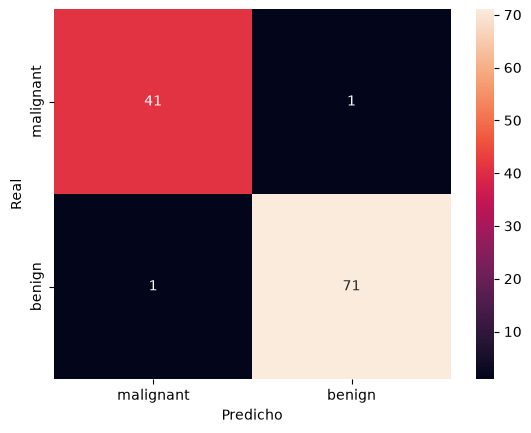

In [ ]:
mejor = mejores_random['Logistic Regression']
y_pred = mejor.predict(X_test)

print(classification_report(y_test, y_pred, target_names=data['target_names']))

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d',
            xticklabels=data['target_names'], yticklabels=data['target_names'])
plt.xlabel('Predicho')
plt.ylabel('Real')
plt.show()

# precision es cuando el modelo predice positivo y es correcto, recall es cuando el modelo predice negativo y es correcto, f1-score es la media armónica de precision y recall.ç
# en test son muy buenos los resultados, con un accuracy del 0.9824561403508771, precision del 0.98, recall del 0.98 y f1-score del 0.98, lo que indica que el modelo es muy bueno para predecir si un tumor es maligno o benigno.